In [4]:
import scanpy as sc
import squidpy as sq
import diffsvg as dvg
import numpy as np

Morphogen example

In [5]:
adata = sc.read_h5ad("/home/lehnerl/Arbeit/data/legnini23.h5ad")

The dataset contains 17 slides (samples) split between two conditions

In [8]:
adata.obs

,Cell,Area,x,y,sample,condition,organoid,obs_names,split
0,A2-1_c1,20162.0,2369.601,1167.102,slide1_A2-1,SHH,organoid #2,A2-1_c1,train
1,A2-1_c2,16096.0,4930.774,1151.607,slide1_A2-1,SHH,organoid #2,A2-1_c2,train
2,A2-1_c3,15117.0,2274.517,1143.662,slide1_A2-1,SHH,organoid #2,A2-1_c3,train
3,A2-1_c4,18353.0,2867.076,1166.651,slide1_A2-1,SHH,organoid #2,A2-1_c4,train
4,A2-1_c5,35266.0,1951.475,1159.566,slide1_A2-1,SHH,organoid #2,A2-1_c5,train
...,...,...,...,...,...,...,...,...,...
43757,W5A3_c1639,5183.0,3217.967,7198.198,slide4_B2-3,Ctrl,organoid #7,W5A3_c1639,val
43758,W5A3_c1640,9650.0,3727.623,7252.018,slide4_B2-3,Ctrl,organoid #7,W5A3_c1640,val
43759,W5A3_c1641,6259.0,3625.728,7206.087,slide4_B2-3,Ctrl,organoid #7,W5A3_c1641,val
43760,W5A3_c1642,4909.0,3170.510,7260.791,slide4_B2-3,Ctrl,organoid #7,W5A3_c1642,val


The morphogen SHH is expressed in a fraction of cells on all slides.

/home/lehnerl/miniconda3/envs/pymc_env/lib/python3.14/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/home/lehnerl/miniconda3/envs/pymc_env/lib/python3.14/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)


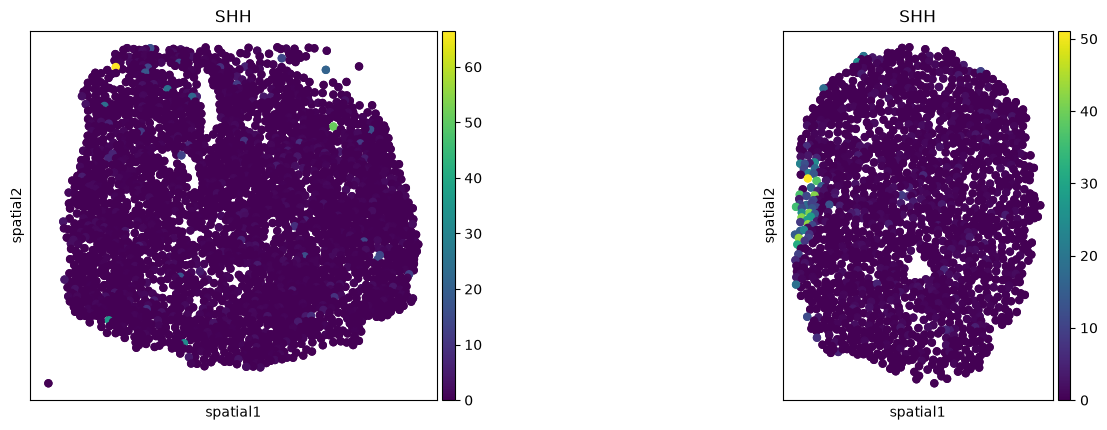

In [3]:
sq.pl.spatial_scatter(adata, color="SHH", library_key="sample", size=100,library_id=["slide1_A2-1","slide4_B2-3"], shape=None)

We want to annotate cells with high SHH expressions and use them as anchor points such that we can measure the signal of other genes by distance w.r.t. the SHH+ cells. Here we use the top 1-percentile for annotation.

In [ ]:
arr = adata.X[:,adata.var_names.get_loc("SHH")].flatten() 
arr_bool = arr > np.percentile(arr, 99)
arr_bool

array([False, False,  True, ..., False, False, False], shape=(43762,))

In [15]:
np.unique(arr_bool, return_counts=True)

(array([False,  True]), array([43324,   438]))

The column that annotates the anchor is named "SHH+"

In [16]:
adata.obs["SHH+"] = arr_bool
adata.obs["SHH+"] = adata.obs["SHH+"].astype(str)

/home/lehnerl/miniconda3/envs/pymc_env/lib/python3.14/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/home/lehnerl/miniconda3/envs/pymc_env/lib/python3.14/site-packages/squidpy/pl/_spatial_utils.py:979: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(
/home/lehnerl/miniconda3/envs/pymc_env/lib/python3.14/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/home/lehnerl/miniconda3/envs/pymc_e

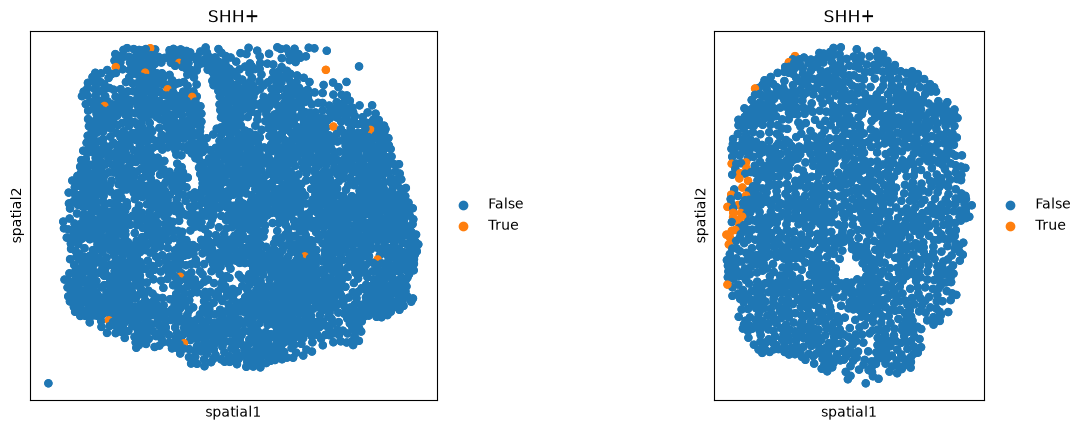

In [17]:
sq.pl.spatial_scatter(adata, color="SHH+", library_key="sample", size=100,library_id=["slide1_A2-1","slide4_B2-3"], shape=None)

Let's calculate the (euclidean) distance of each cell to its closest SHH+ cell:

In [18]:
sq.tl.var_by_distance(
    adata, cluster_key="SHH+", groups="True", library_key="sample", covariates="condition"
)

This yields:

In [13]:
adata.obsm["design_matrix"]

,SHH+,sample,True,True_raw,condition
0,False,slide1_A2-1,0.045167,97.930591,SHH
1,False,slide1_A2-1,0.404672,877.397221,SHH
2,True,slide1_A2-1,NaN,0.000000,SHH
3,False,slide1_A2-1,0.121246,262.882032,SHH
4,False,slide1_A2-1,0.149174,323.433256,SHH
...,...,...,...,...,...
43757,False,slide4_B2-3,0.671884,2784.046909,Ctrl
43758,False,slide4_B2-3,0.780932,3235.904485,Ctrl
43759,False,slide4_B2-3,0.754210,3125.178087,Ctrl
43760,False,slide4_B2-3,0.671955,2784.342940,Ctrl


To accelerate model fitting, we don't fit on the raw data but instead bin our counts by distance intervals and average the expression within each interval.

In [19]:
dvg.pp.bin_obs(
    adata, genes=adata.var_names, anchor="True", condition="condition", design_matrix="design_matrix", n_bins=50
)

/home/lehnerl/Arbeit/github/HiWi/diffsvg/src/diffsvg/pp/utils.py:378: RuntimeWarning: invalid value encountered in cast
  bin_assignment = np.clip(np.rint(all_anchor_vals * n_bins).astype(int), 0, n_bins)


We define the model using default parameter values:

In [20]:
setup = dvg.tl.setup_model(adata)

Each gene requires a separate model, we fit 4 in parallel:

In [21]:
dvg.tl.fit_model(adata, setup, n_workers=4)

Fitting DiffSVG models:   0%|          | 0/88 [00:00<?, ?it/s]

Fitting DiffSVG models:  51%|█████     | 45/88 [01:33<01:40,  2.33s/it]/home/lehnerl/miniconda3/envs/pymc_env/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
Fitting DiffSVG models: 100%|██████████| 88/88 [02:57<00:00,  2.02s/it]


We can visualize the results in a volcano plot and annotate the most significant genes. Note: the genes are ordered by an empirical p-value here.

<Axes: xlabel='$\\Delta_{f_0 - f_1}$', ylabel='$-\\log_{10}(p)$'>

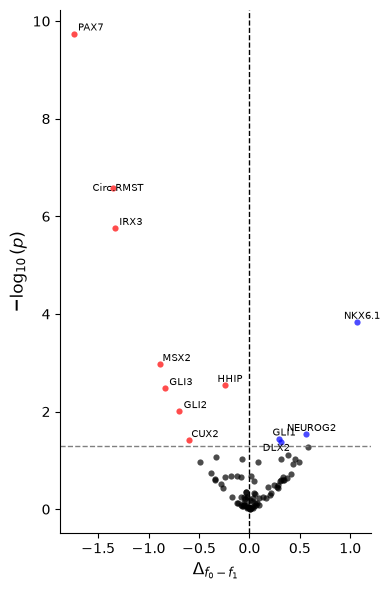

In [22]:
dvg.pl.plot_volcano(adata.varm["dsvg_stats"], n_label=20)

The Delta serves as a log-fold-change here. Since gene expression is measured across distance we check the area between the two curves and treat the condition whose curve is covering a larger area as the one where a gene is upregulated. Let's visualize 4 tops genes, two upregulated in condition 0 and two upregulated in condition 1 respectively:

[<Axes: title={'center': 'PAX7'}, xlabel='Normalized distance', ylabel='smoothed expression'>,
 <Axes: title={'center': 'IRX3'}, xlabel='Normalized distance', ylabel='smoothed expression'>,
 <Axes: title={'center': 'NKX6.1'}, xlabel='Normalized distance', ylabel='smoothed expression'>,
 <Axes: title={'center': 'GLI1'}, xlabel='Normalized distance', ylabel='smoothed expression'>]

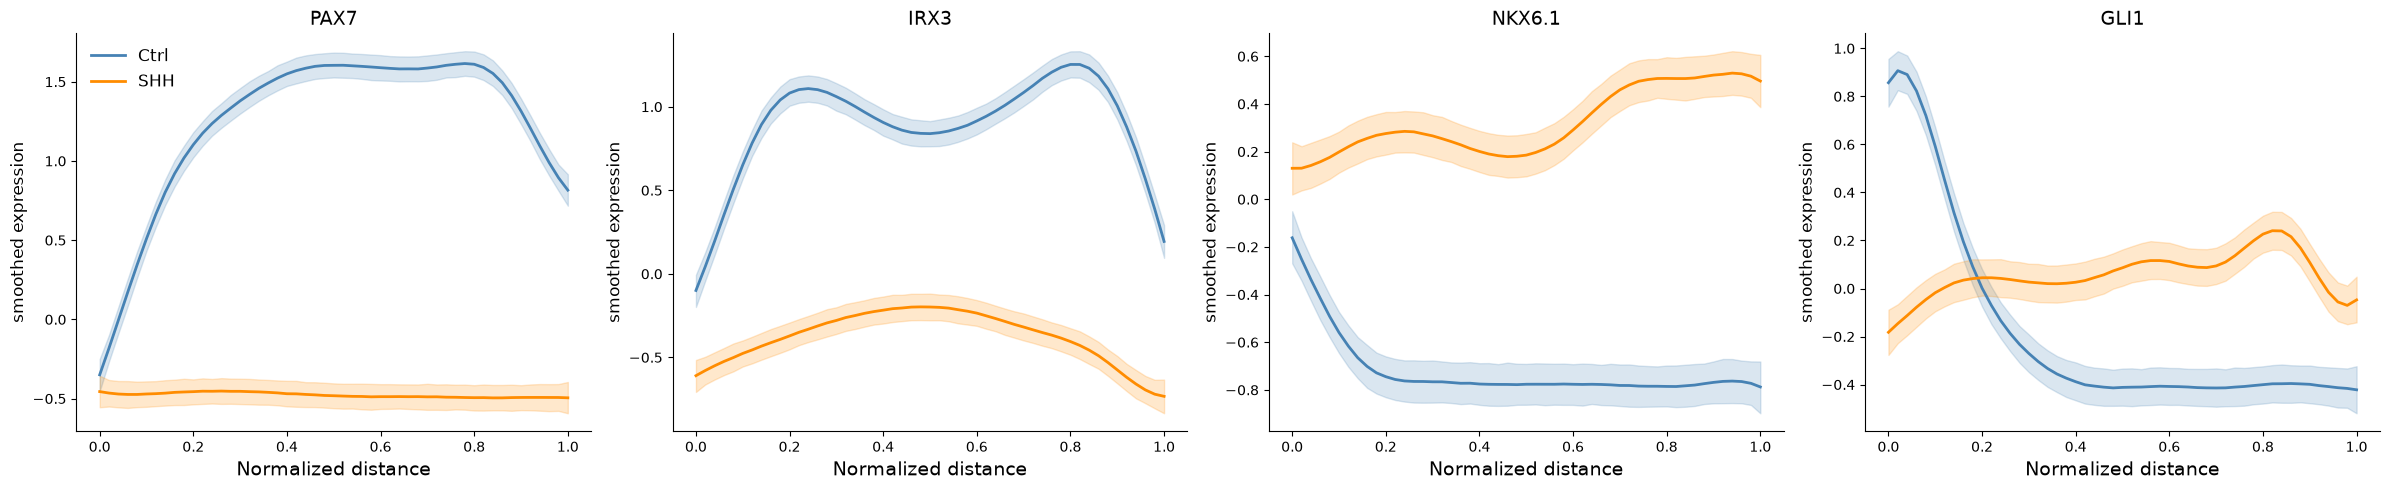

In [14]:
dvg.pl.plot_prediction_curve(adata, gene=["PAX7","IRX3", "NKX6.1","GLI1"])